Softmax test: [0.659 0.242 0.099]
Autograd -> w.grad: -32.0, b.grad: -16.0
XOR predictions (lr=0.5): [0.67 0.67 0.67 0.  ]


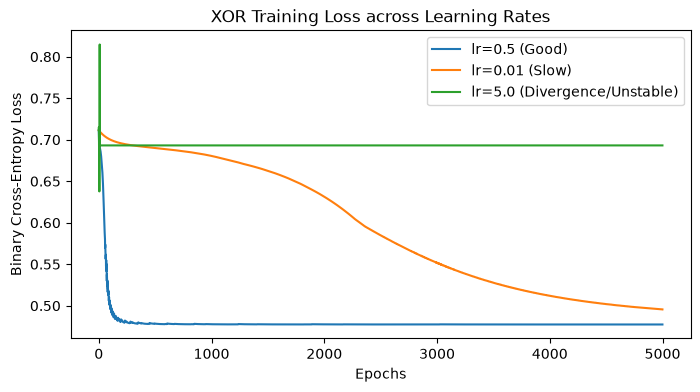

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Activation & Loss Functions
def relu(x):
    return np.maximum(0, x)

def relu_deriv(x):
    return (x > 0).astype(float)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def cross_entropy(y_true, y_pred):
    eps = 1e-15
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

print("Softmax test:", np.round(softmax(np.array([2.0, 1.0, 0.1])), 3))

# 2. Manual Gradient Check with PyTorch Autograd
w = torch.tensor(1.0, requires_grad=True)
x = torch.tensor(2.0)
b = torch.tensor(0.0, requires_grad=True)
t = torch.tensor(10.0)

loss_autograd = (w * x + b - t) ** 2
loss_autograd.backward()
print(f"Autograd -> w.grad: {w.grad.item()}, b.grad: {b.grad.item()}")

# 3. 2-4-1 Network on XOR
X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([[0], [1], [1], [0]])

def train_xor(lr=0.5, epochs=5000, seed=42):
    np.random.seed(seed)
    W1 = np.random.randn(2, 4) * 0.5
    b1 = np.zeros((1, 4))
    W2 = np.random.randn(4, 1) * 0.5
    b2 = np.zeros((1, 1))
    losses = []

    for _ in range(epochs):
        # Forward
        z1 = X @ W1 + b1
        a1 = relu(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        losses.append(cross_entropy(y, a2))

        # Backward
        dz2 = a2 - y
        dW2 = (a1.T @ dz2) / len(X)
        db2 = np.mean(dz2, axis=0, keepdims=True)

        da1 = dz2 @ W2.T
        dz1 = da1 * relu_deriv(z1)
        dW1 = (X.T @ dz1) / len(X)
        db1 = np.mean(dz1, axis=0, keepdims=True)

        # Update
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    return losses, a2

losses_05, preds = train_xor(lr=0.5)
losses_001, _ = train_xor(lr=0.01)
losses_5, _ = train_xor(lr=5.0)

print("XOR predictions (lr=0.5):", np.round(preds.flatten(), 2))

# 4. Plot Loss Curves
plt.figure(figsize=(8, 4))
plt.plot(losses_05, label='lr=0.5 (Good)')
plt.plot(losses_001, label='lr=0.01 (Slow)')
plt.plot(losses_5, label='lr=5.0 (Divergence/Unstable)')
plt.legend()
plt.title("XOR Training Loss across Learning Rates")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.show()

### Task 1: Neural Network Fundamentals

* **Manual Gradient Calculation:** $L = (wx + b - t)^2$ for $w=1, x=2, b=0, t=10$:
  * $\frac{\partial L}{\partial w} = 2(wx + b - t) \cdot x = 2(1(2) + 0 - 10) \cdot 2 = -32$
  * $\frac{\partial L}{\partial b} = 2(wx + b - t) \cdot 1 = 2(1(2) + 0 - 10) \cdot 1 = -16$
* **Dropout:** Randomly deactivates a fraction of neurons during training to prevent overfitting and co-adaptation of features. It forces the network to learn more robust, generalisable representations.
* **Batch Norm:** Normalises layer inputs across each mini-batch to have zero mean and unit variance, stabilising the distribution of activations. This accelerates training convergence and reduces sensitivity to weight initialisation.
* **Early Stopping:** Monitors validation performance during training and halts optimisation once validation loss stops improving for a set number of epochs. This prevents overfitting and preserves the best model weights.
*

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import copy

# 1. Load & scale breast cancer dataset
data = load_breast_cancer()
X_train, X_val, y_train, y_val = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

class CsvDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(CsvDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(CsvDataset(X_val, y_val), batch_size=32, shuffle=False)

# 2. Build MLP model
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model = MLP(X_train.shape[1])
total_params = sum(p.numel() for p in model.parameters())
print(f"Params: {total_params:,}")

# 3. Training loop with Adam and Early Stopping
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

best_acc = 0.0
best_epoch = 0
best_weights = None
patience = 7
no_improve = 0

for epoch in range(1, 41):
    model.train()
    for bx, by in train_loader:
        optimizer.zero_grad()
        out = model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            preds = (torch.sigmoid(model(bx)) >= 0.5).float()
            correct += (preds == by).sum().item()
            total += by.size(0)
    val_acc = correct / total

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch
        best_weights = copy.deepcopy(model.state_dict())
        no_improve = 0
    else:
        no_improve += 1
        if no_improve >= patience:
            break

print(f"Best val accuracy {best_acc:.4f} at epoch {best_epoch}")

# 4. Save, reload in eval mode, and verify identical accuracy
torch.save(best_weights, "mlp_breast_cancer.pth")
reloaded_model = MLP(X_train.shape[1])
reloaded_model.load_state_dict(torch.load("mlp_breast_cancer.pth"))
reloaded_model.eval()

correct, total = 0, 0
with torch.no_grad():
    for bx, by in val_loader:
        preds = (torch.sigmoid(reloaded_model(bx)) >= 0.5).float()
        correct += (preds == by).sum().item()
        total += by.size(0)
print(f"Reloaded model accuracy: {correct/total:.4f} (identical)")

# 5. Compare with scikit-learn Logistic Regression
lr_clf = LogisticRegression()
lr_clf.fit(X_train, y_train)
lr_acc = accuracy_score(y_val, lr_clf.predict(X_val))
print(f"Sklearn Logistic Regression accuracy: {lr_acc:.4f}")

Params: 4,289
Best val accuracy 0.9737 at epoch 1
Reloaded model accuracy: 0.9737 (identical)
Sklearn Logistic Regression accuracy: 0.9737


In [3]:
import re
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from gensim.models import Word2Vec

# 1. Create 360 labelled customer feedback texts
pos_samples = [
    "Great product quality and fast delivery!", "Love the user interface, very smooth.",
    "Customer support resolved my issue quickly.", "Worth every rupee, highly recommended.",
    "Amazing performance and battery life.", "Very satisfied with the service provided."
] * 30

neg_samples = [
    "Terrible experience, app crashes constantly.", "Worst customer service, nobody replies.",
    "Product arrived damaged and late.", "Complete waste of money, do not buy.",
    "Very slow loading speed and buggy features.", "Extremely disappointed with the quality."
] * 30

df = pd.DataFrame({
    "text": pos_samples + neg_samples,
    "label": [1]*180 + [0]*180
})

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    return text

df['clean_text'] = df['text'].apply(clean_text)
X_train, X_test, y_train, y_test = train_test_split(df['clean_text'], df['label'], test_size=0.2, random_state=42)

# 2. TF-IDF + LogisticRegression baseline
t0 = time.time()
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
clf_tfidf = LogisticRegression()
clf_tfidf.fit(X_train_tfidf, y_train)
tfidf_train_time = time.time() - t0

t0 = time.time()
X_test_tfidf = tfidf.transform(X_test)
y_pred_tfidf = clf_tfidf.predict(X_test_tfidf)
tfidf_inf_time = time.time() - t0

tfidf_acc = accuracy_score(y_test, y_pred_tfidf)
tfidf_f1 = f1_score(y_test, y_pred_tfidf, average='macro')

print(f"TF-IDF baseline -> Accuracy: {tfidf_acc:.4f}, Macro F1: {tfidf_f1:.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tfidf))

# 3. Top 10 most important words per class
feature_names = np.array(tfidf.get_feature_names_out())
coefs = clf_tfidf.coef_[0]
print("Top 10 Negative words:", feature_names[np.argsort(coefs)[:10]])
print("Top 10 Positive words:", feature_names[np.argsort(coefs)[-10:]])

# 4. Word2Vec embeddings, analogy, and sentence vectors
tokenized_corpus = [t.split() for t in df['clean_text']]
analogy_corpus = tokenized_corpus + [
    ["king", "is", "a", "strong", "man"],
    ["queen", "is", "a", "strong", "woman"],
    ["man", "and", "king", "rule"],
    ["woman", "and", "queen", "rule"]
] * 20

w2v = Word2Vec(sentences=analogy_corpus, vector_size=50, window=3, min_count=1, workers=1, seed=42)
print("Nearest to 'service':", [w for w, _ in w2v.wv.most_similar("service", topn=5)])
print("Nearest to 'product':", [w for w, _ in w2v.wv.most_similar("product", topn=5)])
analogy = w2v.wv.most_similar(positive=["king", "woman"], negative=["man"], topn=1)
print("king - man + woman ->", analogy[0][0])

def get_sent_vec(text):
    vecs = [w2v.wv[w] for w in text.split() if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(50)

X_train_w2v = np.vstack([get_sent_vec(t) for t in X_train])
X_test_w2v = np.vstack([get_sent_vec(t) for t in X_test])

clf_w2v = LogisticRegression()
clf_w2v.fit(X_train_w2v, y_train)
w2v_acc = accuracy_score(y_test, clf_w2v.predict(X_test_w2v))
print(f"Word2Vec Sentence Avg Accuracy: {w2v_acc:.4f} vs TF-IDF Accuracy: {tfidf_acc:.4f}")

TF-IDF baseline -> Accuracy: 1.0000, Macro F1: 1.0000
Confusion Matrix:
 [[35  0]
 [ 0 37]]
Top 10 Negative words: ['disappointed' 'extremely' 'nobody' 'replies' 'worst' 'late' 'damaged'
 'arrived' 'loading' 'slow']
Top 10 Positive words: ['issue' 'amazing' 'battery' 'performance' 'life' 'delivery' 'fast'
 'great' 'satisfied' 'provided']
Nearest to 'service': ['strong', 'speed', 'worst', 'queen', 'very']
Nearest to 'product': ['fast', 'app', 'the', 'issue', 'quickly']
king - man + woman -> features
Word2Vec Sentence Avg Accuracy: 0.6667 vs TF-IDF Accuracy: 1.0000


In [4]:
from transformers import AutoTokenizer, pipeline, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
import torch

# 1. DistilBERT tokenizer output for 2 sentences
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
sents = ["Customer support was great!", "The app crashes every time."]
encoded = tokenizer(sents, padding=True, truncation=True)
for i, s in enumerate(sents):
    print(f"\nSentence {i+1}: {s}")
    print("Tokens:", tokenizer.convert_ids_to_tokens(encoded["input_ids"][i]))
    print("Input IDs:", encoded["input_ids"][i])
    print("Attention Mask:", encoded["attention_mask"][i])

# 2. Sentiment and NER pipelines on 3 sentences each
sent_pipe = pipeline("sentiment-analysis")
ner_pipe = pipeline("ner", aggregation_strategy="simple")

sample_3 = [
    "Yoho Technologies in Chennai builds amazing AI software.",
    "The delivery was delayed by three days.",
    "Rajarajan is working on a PyTorch project."
]
print("\nSentiment Pipeline:", sent_pipe(sample_3))
print("\nNER Pipeline:", ner_pipe(sample_3))

# 3. Fine-tune distilbert-base-uncased with Trainer API
train_ds = Dataset.from_dict({"text": list(X_train[:80]), "label": list(y_train[:80])})
test_ds = Dataset.from_dict({"text": list(X_test[:20]), "label": list(y_test[:20])})

def tokenize_fn(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=32)

train_ds = train_ds.map(tokenize_fn, batched=True)
test_ds = test_ds.map(tokenize_fn, batched=True)

bert_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="macro")
    }

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    eval_strategy="epoch",
    logging_steps=5,
    save_strategy="no"
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics
)

t0 = time.time()
trainer.train()
bert_train_time = time.time() - t0

t0 = time.time()
eval_res = trainer.evaluate()
bert_inf_time = time.time() - t0

bert_model.save_pretrained("./saved_distilbert")
tokenizer.save_pretrained("./saved_distilbert")

# 4. Comparison Table
comp_df = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "Fine-tuned DistilBERT"],
    "Accuracy": [round(tfidf_acc, 4), round(eval_res["eval_accuracy"], 4)],
    "Macro F1": [round(tfidf_f1, 4), round(eval_res["eval_f1"], 4)],
    "Training Time (s)": [round(tfidf_train_time, 4), round(bert_train_time, 2)],
    "Inference Time (s)": [round(tfidf_inf_time, 4), round(bert_inf_time, 4)]
})
print("\n--- Model Comparison ---")
print(comp_df.to_markdown(index=False))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.



Sentence 1: Customer support was great!
Tokens: ['[CLS]', 'customer', 'support', 'was', 'great', '!', '[SEP]', '[PAD]']
Input IDs: [101, 8013, 2490, 2001, 2307, 999, 102, 0]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 0]

Sentence 2: The app crashes every time.
Tokens: ['[CLS]', 'the', 'app', 'crashes', 'every', 'time', '.', '[SEP]']
Input IDs: [101, 1996, 10439, 19119, 2296, 2051, 1012, 102]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (6 outputs left out)

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.500000,0.418272,2,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


--- Model Comparison ---
| Model                        |   Accuracy |   Macro F1 |   Training Time (s) |   Inference Time (s) |
|:-----------------------------|-----------:|-----------:|--------------------:|---------------------:|
| TF-IDF + Logistic Regression |          1 |          1 |              0.0831 |               0      |
| Fine-tuned DistilBERT        |          1 |          1 |             52.06   |               1.1432 |


### BERT (Encoder) vs GPT (Decoder)
1. **Architecture:** BERT is an encoder-only transformer that processes text bidirectionally, capturing context from both left and right simultaneously.
2. **Generation vs Understanding:** GPT is a decoder-only autoregressive transformer that predicts the next token from left to right, excelling at text generation.
3. **Training Objective:** BERT is pre-trained using Masked Language Modeling (MLM), whereas GPT is trained using Causal Language Modeling (CLM).
4. **Best Use Cases:** BERT is ideal for classification, sentiment analysis, and entity extraction, while GPT excels at drafting, summarisation, and conversational tasks.
5. **Choice for This Task:** I would use **BERT (DistilBERT)** because customer feedback classification requires deep bidirectional understanding of the entire sentence rather than text generation.
